In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from src.preprocess import load_raw, clean, clean_labels

In [3]:
raw = load_raw("../data/raw")
print(raw.shape)
raw_counts = clean_labels(raw["Label"]).value_counts()

(2830743, 79)


In [4]:
before = len(raw)
data = clean(raw)
del raw
print(f"Rows: {before:,} -> {len(data):,}  (removed {before - len(data):,})")

num = data.select_dtypes("number")
print("Infinite:", np.isinf(num).sum().sum())
print("Missing:", data.isna().sum().sum())
print("Duplicates:", data.duplicated().sum())
print(data["Label"].value_counts())

Rows: 2,830,743 -> 2,498,185  (removed 332,558)
Infinite: 0
Missing: 0
Duplicates: 0
Label
BENIGN                        2072444
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


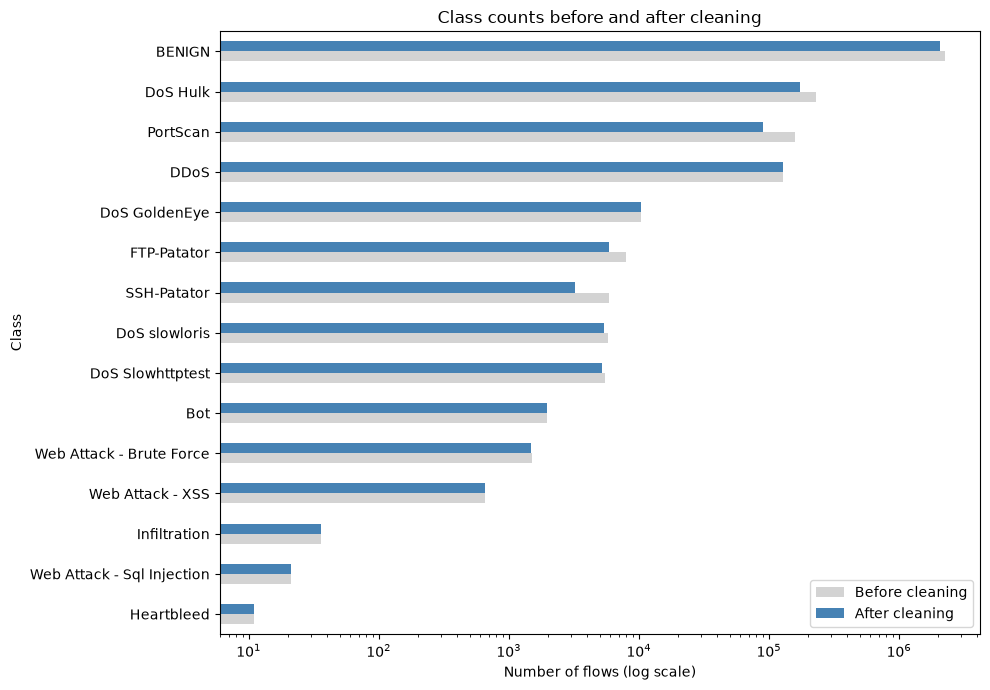

In [5]:
after_counts = data["Label"].value_counts()
cmp = pd.DataFrame({"Before cleaning": raw_counts, "After cleaning": after_counts}).sort_values("Before cleaning")

ax = cmp.plot(kind="barh", figsize=(10, 7), color=["lightgray", "steelblue"], logx=True)
ax.set_xlabel("Number of flows (log scale)")
ax.set_ylabel("Class")
ax.set_title("Class counts before and after cleaning")
plt.tight_layout()
plt.savefig("../results/figures/cleaning_before_after.png", dpi=150)
plt.show()

In [6]:
MAX_PER_CLASS = 60000
parts = [g.sample(n=min(len(g), MAX_PER_CLASS), random_state=42)
         for _, g in data.groupby("Label")]
sampled = pd.concat(parts, ignore_index=True)
print(sampled["Label"].value_counts())
print("Sampled shape:", sampled.shape)

Path("../data/processed").mkdir(parents=True, exist_ok=True)
sampled.to_parquet("../data/processed/clean_sampled.parquet")
data.to_parquet("../data/processed/clean_full.parquet")

Label
BENIGN                        60000
DDoS                          60000
DoS Hulk                      60000
PortScan                      60000
DoS GoldenEye                 10286
FTP-Patator                    5931
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1948
Web Attack - Brute Force       1470
Web Attack - XSS                652
Infiltration                     36
Web Attack - Sql Injection       21
Heartbleed                       11
Name: count, dtype: int64
Sampled shape: (274187, 79)
